# Assignment 4 – Task 1: Sequential Kannada-MNIST Classification
Each 28×28 image is fed to an RNN / LSTM / GRU as **T = 28 timesteps**, where the input at step *t* is row *t* (a 28-dim vector). Pixels are scaled to [0, 1].

**Setup:** place the uploaded dataset zip (or the extracted folder) in the same directory as this notebook (or change `DATA_ROOT`).

In [3]:
import os, glob, zipfile, random, time
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Load data, normalise, split (train / validation / held-out test)
Uses `Dig-MNIST.csv` (10,240 labelled 28×28 Kannada digit images). Upload the csv or its zip to the Colab file panel.

In [4]:
ROOTS = [".", "/content", "/kaggle/input"]

def find_csv(name="Dig-MNIST.csv"):
    # 1) the csv itself (files only, folders are ignored)
    for r in ROOTS:
        for f in glob.glob(os.path.join(r, "**", name), recursive=True):
            if os.path.isfile(f): return f
    # 2) the csv inside any uploaded zip
    for r in ROOTS:
        for z in glob.glob(os.path.join(r, "**", "*.zip"), recursive=True):
            try:
                with zipfile.ZipFile(z) as zf:
                    for member in zf.namelist():
                        if os.path.basename(member) == name:
                            zf.extract(member, "data")
                            return os.path.join("data", member)
            except zipfile.BadZipFile:
                pass
    raise FileNotFoundError(f"{name} not found. Files in current folder: {os.listdir('.')}")

df = pd.read_csv(find_csv())                        # Dig-MNIST.csv: label + 784 pixel columns (10,240 images)
y_all = df["label"].values
X_all = df.drop(columns="label").values.reshape(-1, 28, 28)

# Pixel normalisation: [0, 255] -> [0, 1];  shape (N, 28, 28) = (N, T=28 rows, 28 features)
X_all = X_all.astype(np.float32) / 255.0

# Stratified split: 72 % train / 8 % validation / 20 % held-out test
X_full, X_test, y_full, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_full, y_full, test_size=0.1, stratify=y_full, random_state=SEED)
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)
print("pixel range:", X_train.min(), "-", X_train.max())

def make_loader(X, y, shuffle, bs=256):
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X)),
                       torch.from_numpy(y.astype(np.int64)))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

train_loader      = make_loader(X_train, y_train, True)
train_eval_loader = make_loader(X_train, y_train, False)
val_loader        = make_loader(X_val, y_val, False)
test_loader       = make_loader(X_test, y_test, False)

train (7372, 28, 28) val (820, 28, 28) test (2048, 28, 28)
pixel range: 0.0 - 1.0


## 2. Qualitative visualisation – 5 sample heatmaps per class (rows = digits 0–9)

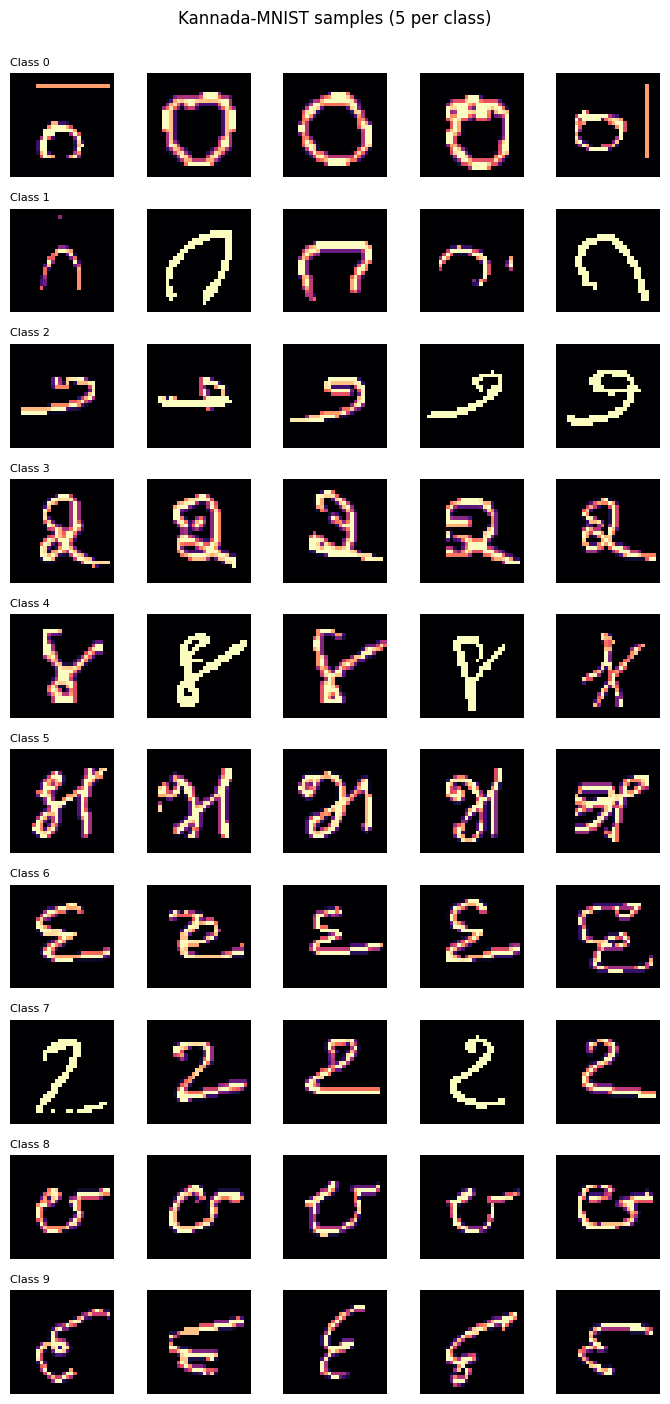

In [5]:
fig, axes = plt.subplots(10, 5, figsize=(7, 14))
for d in range(10):
    idx = np.where(y_full == d)[0][:5]
    for j, i in enumerate(idx):
        axes[d, j].imshow(X_full[i], cmap="magma"); axes[d, j].axis("off")
    axes[d, 0].set_title(f"Class {d}", fontsize=8, loc="left")
plt.suptitle("Kannada-MNIST samples (5 per class)", y=1.0); plt.tight_layout(); plt.show()

## 3. Model, training loop (convergence: |L(k) − L(k−1)| < 1e-4)

In [6]:
class SeqClassifier(nn.Module):
    def __init__(self, cell, hidden, layers):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(28, hidden, num_layers=layers, batch_first=True)
        self.fc = nn.Linear(hidden, 10)
    def forward(self, x):                 # x: (B, 28 timesteps, 28 features)
        out, _ = self.rnn(x)
        return self.fc(out[:, -1])        # last timestep -> 10 classes

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(model(x.to(device)).argmax(1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def accuracy(model, loader):
    p, y = predict(model, loader)
    return float((p == y).mean())

def train(cell, hidden, layers, lr=1e-3, tol=1e-4, max_epochs=30):
    model = SeqClassifier(cell, hidden, layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    losses, gnorms = [], []
    for ep in range(max_epochs):          # max_epochs is only a safety cap
        model.train(); tot = gn = n = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y); loss.backward()
            gn += nn.utils.clip_grad_norm_(model.parameters(), 5.0).item() * len(x)
            opt.step()
            tot += loss.item() * len(x); n += len(x)
        losses.append(tot / n); gnorms.append(gn / n)
        if ep > 0 and abs(losses[-1] - losses[-2]) < tol:
            break
    return model, losses, gnorms

## 4. Hyper-parameter search: cell type × #layers × hidden units

In [7]:
grid = [(c, l, h) for c in ["RNN", "LSTM", "GRU"] for l in [1, 2] for h in [64, 128]]
rows, hist, models = [], {}, {}
for c, l, h in grid:
    name = f"{c}-L{l}-H{h}"
    t0 = time.time()
    model, losses, gn = train(c, h, l)
    hist[name] = (c, losses, gn); models[name] = model
    rows.append({"Config": name, "Cell": c, "Layers": l, "Hidden": h, "Epochs": len(losses),
                 "Final Loss": losses[-1], "Mean Grad Norm": float(np.mean(gn)),
                 "Train Acc": accuracy(model, train_eval_loader),
                 "Val Acc": accuracy(model, val_loader),
                 "Test Acc": accuracy(model, test_loader)})
    print(f"{name:14s} epochs={len(losses):2d} train={rows[-1]['Train Acc']:.4f} "
          f"val={rows[-1]['Val Acc']:.4f} test={rows[-1]['Test Acc']:.4f} ({time.time()-t0:.0f}s)")
results = pd.DataFrame(rows)

RNN-L1-H64     epochs=30 train=0.8262 val=0.7939 test=0.8008 (12s)
RNN-L1-H128    epochs=30 train=0.8642 val=0.8268 test=0.8335 (4s)
RNN-L2-H64     epochs=30 train=0.8833 val=0.8537 test=0.8506 (4s)
RNN-L2-H128    epochs=30 train=0.9285 val=0.8866 test=0.8843 (5s)
LSTM-L1-H64    epochs=30 train=0.9426 val=0.8890 test=0.8882 (4s)
LSTM-L1-H128   epochs=30 train=0.9662 val=0.9049 test=0.9121 (5s)
LSTM-L2-H64    epochs=30 train=0.9509 val=0.8915 test=0.8945 (5s)
LSTM-L2-H128   epochs=30 train=0.9928 val=0.9122 test=0.9277 (8s)
GRU-L1-H64     epochs=30 train=0.9364 val=0.8841 test=0.8979 (6s)
GRU-L1-H128    epochs=30 train=0.9533 val=0.9110 test=0.9072 (4s)
GRU-L2-H64     epochs=30 train=0.9577 val=0.9049 test=0.9126 (5s)
GRU-L2-H128    epochs=30 train=0.9894 val=0.9366 test=0.9365 (6s)


## 5. Summary table (training & test accuracy for every hyper-parameter set)

In [8]:
display(results.round(4))
print("\nAverages per cell type:")
display(results.groupby("Cell")[["Epochs", "Final Loss", "Mean Grad Norm", "Train Acc", "Test Acc"]].mean().round(4))

,Config,Cell,Layers,Hidden,Epochs,Final Loss,Mean Grad Norm,Train Acc,Val Acc,Test Acc
0,RNN-L1-H64,RNN,1,64,30,0.5671,3.3132,0.8262,0.7939,0.8008
1,RNN-L1-H128,RNN,1,128,30,0.4440,4.0951,0.8642,0.8268,0.8335
2,RNN-L2-H64,RNN,2,64,30,0.4120,4.0511,0.8833,0.8537,0.8506
3,RNN-L2-H128,RNN,2,128,30,0.2515,3.3759,0.9285,0.8866,0.8843
4,LSTM-L1-H64,LSTM,1,64,30,0.1805,2.2683,0.9426,0.8890,0.8882
5,LSTM-L1-H128,LSTM,1,128,30,0.1074,2.7370,0.9662,0.9049,0.9121
6,LSTM-L2-H64,LSTM,2,64,30,0.1505,2.3437,0.9509,0.8915,0.8945
7,LSTM-L2-H128,LSTM,2,128,30,0.0517,1.9203,0.9928,0.9122,0.9277
8,GRU-L1-H64,GRU,1,64,30,0.2392,1.3308,0.9364,0.8841,0.8979
9,GRU-L1-H128,GRU,1,128,30,0.1818,1.3646,0.9533,0.9110,0.9072



Averages per cell type:


,Epochs,Final Loss,Mean Grad Norm,Train Acc,Test Acc
Cell,,,,,
GRU,30.0,0.1567,1.1794,0.9592,0.9136
LSTM,30.0,0.1225,2.3173,0.9631,0.9056
RNN,30.0,0.4186,3.7088,0.8756,0.8423


## 6. Average training error vs. epochs, and gradient norm vs. epochs

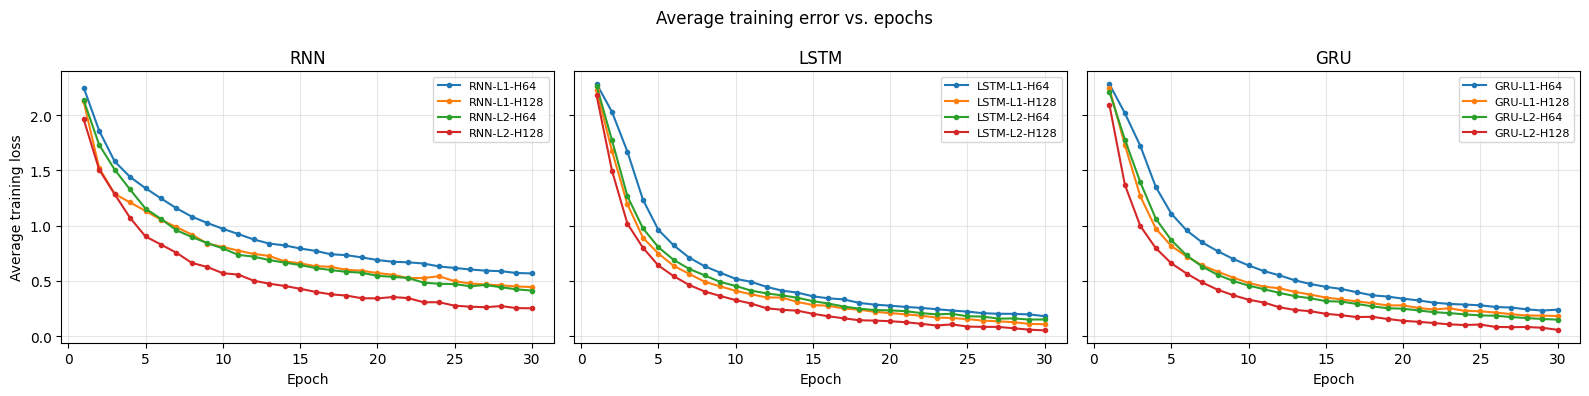

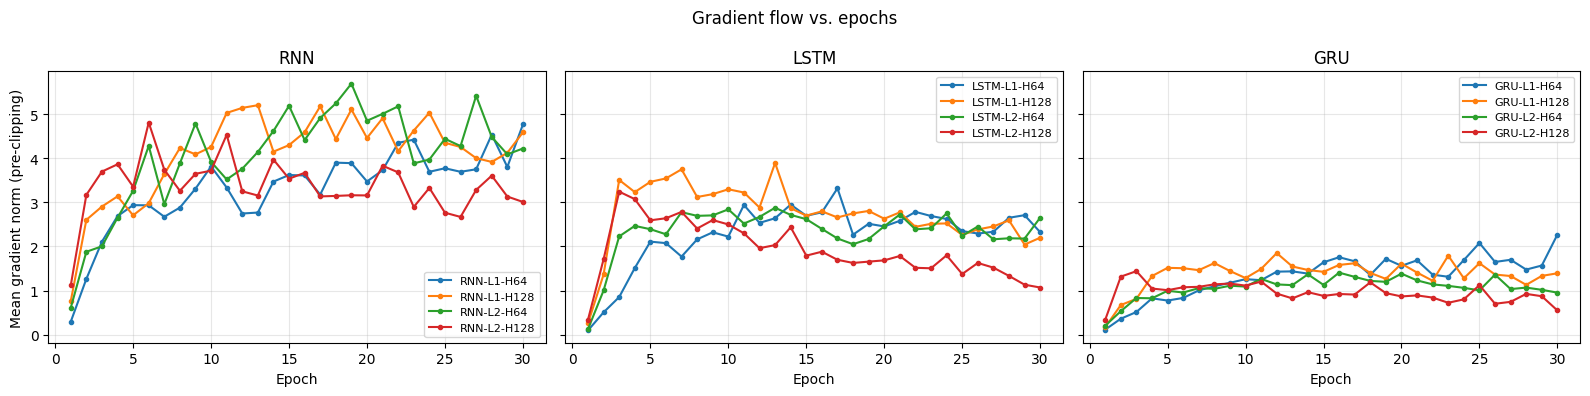

In [9]:
def plot_hist(idx, ylabel, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, c in zip(axes, ["RNN", "LSTM", "GRU"]):
        for name, (cell, *vals) in hist.items():
            if cell == c: ax.plot(range(1, len(vals[idx]) + 1), vals[idx], marker="o", ms=3, label=name)
        ax.set_title(c); ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    axes[0].set_ylabel(ylabel); plt.suptitle(title); plt.tight_layout(); plt.show()

plot_hist(0, "Average training loss", "Average training error vs. epochs")
plot_hist(1, "Mean gradient norm (pre-clipping)", "Gradient flow vs. epochs")

## 7. Best configuration (selected by validation accuracy): metrics + confusion matrix

Best config: GRU-L2-H128  (epochs to converge: 30)
Train accuracy: 0.9894 | Val accuracy: 0.9366 | Test accuracy: 0.9365


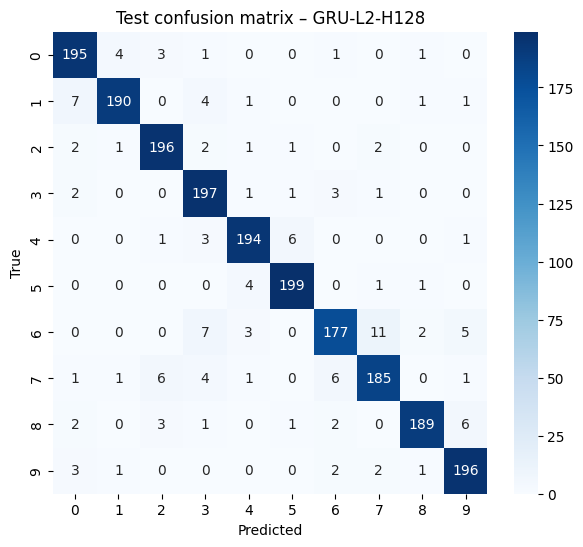

              precision    recall  f1-score   support

           0     0.9198    0.9512    0.9353       205
           1     0.9645    0.9314    0.9476       204
           2     0.9378    0.9561    0.9469       205
           3     0.8995    0.9610    0.9292       205
           4     0.9463    0.9463    0.9463       205
           5     0.9567    0.9707    0.9637       205
           6     0.9267    0.8634    0.8939       205
           7     0.9158    0.9024    0.9091       205
           8     0.9692    0.9265    0.9474       204
           9     0.9333    0.9561    0.9446       205

    accuracy                         0.9365      2048
   macro avg     0.9370    0.9365    0.9364      2048
weighted avg     0.9370    0.9365    0.9364      2048



In [10]:
best = results.loc[results["Val Acc"].idxmax()]
best_model = models[best["Config"]]
print(f"Best config: {best['Config']}  (epochs to converge: {best['Epochs']})")
print(f"Train accuracy: {best['Train Acc']:.4f} | Val accuracy: {best['Val Acc']:.4f} | Test accuracy: {best['Test Acc']:.4f}")

pred, true = predict(best_model, test_loader)
cm = confusion_matrix(true, pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Test confusion matrix – {best['Config']}"); plt.show()
print(classification_report(true, pred, digits=4))